In [6]:
import sys
import pandas as pd
import sklearn

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Executável:", sys.executable)

Python: 3.12.3
Pandas: 3.1.0
Scikit-learn: 1.9.1
Executável: /media/jandersongustavo/f8223ea0-bc74-41e8-8f66-650dbe31ee07/Arquivos_Janderson/Documentos/Projetos/us-gun-policy-ml/.venv/bin/python


In [8]:
import pandas as pd

url = "https://data.cdc.gov/resource/fpsi-y8tj.csv?$limit=5"

amostra = pd.read_csv(url)

display(amostra)
print("Colunas:", amostra.columns.tolist())

,geoid,name,intent,period,count_sup,rate,data_as_of,ttm_date_range
0,2,Alaska,All_Homicide,TTM,48,6.5,2026-10-13T00:00:00.000,"June, 2025 to May, 2026"
1,4,Arizona,FA_Deaths,TTM,1338,18.0,2026-10-13T00:00:00.000,"June, 2025 to May, 2026"
2,4,Arizona,FA_Homicide,TTM,283,3.8,2026-10-13T00:00:00.000,"June, 2025 to May, 2026"
3,4,Arizona,FA_Suicide,TTM,986,13.3,2026-10-13T00:00:00.000,"June, 2025 to May, 2026"
4,5,Arkansas,All_Homicide,TTM,227,7.4,2026-10-13T00:00:00.000,"June, 2025 to May, 2026"


Colunas: ['geoid', 'name', 'intent', 'period', 'count_sup', 'rate', 'data_as_of', 'ttm_date_range']


In [9]:
import pandas as pd

url_periodos = (
    "https://data.cdc.gov/resource/fpsi-y8tj.csv"
    "?$select=period,count(*)"
    "&$group=period"
)

periodos = pd.read_csv(url_periodos)

display(periodos)

,period,count
0,2019,306
1,2020,306
2,2021,306
3,2022,306
4,2023,306
5,2024,306
6,TTM,306


In [1]:
import pandas as pd
import requests

url = "https://data.cdc.gov/resource/fpsi-y8tj.csv"

params = {
    "$where": "intent='All_Homicide' AND period='2024'",
    "$limit": 100
}

resposta = requests.get(url, params=params, timeout=30)
resposta.raise_for_status()

print("Status HTTP:", resposta.status_code)
print("URL consultada:", resposta.url)

from io import StringIO

homicidios_2024 = pd.read_csv(StringIO(resposta.text))

print("Registros:", len(homicidios_2024))
display(homicidios_2024.head(10))

Status HTTP: 200
URL consultada: https://data.cdc.gov/resource/fpsi-y8tj.csv?%24where=intent%3D%27All_Homicide%27+AND+period%3D%272024%27&%24limit=100
Registros: 51


,geoid,name,intent,period,count_sup,rate,data_as_of,ttm_date_range
0,1,Alabama,All_Homicide,2024,645,12.6,2026-06-22T00:00:00.000,NaN
1,2,Alaska,All_Homicide,2024,56,7.6,2026-06-22T00:00:00.000,NaN
2,4,Arizona,All_Homicide,2024,467,6.3,2026-06-22T00:00:00.000,NaN
3,5,Arkansas,All_Homicide,2024,247,8.1,2026-06-22T00:00:00.000,NaN
4,6,California,All_Homicide,2024,1768,4.5,2026-06-22T00:00:00.000,NaN
5,8,Colorado,All_Homicide,2024,305,5.2,2026-06-22T00:00:00.000,NaN
6,9,Connecticut,All_Homicide,2024,104,2.9,2026-06-22T00:00:00.000,NaN
7,10,Delaware,All_Homicide,2024,67,6.5,2026-06-22T00:00:00.000,NaN
8,11,District of Columbia,All_Homicide,2024,172,25.3,2026-06-22T00:00:00.000,NaN
9,12,Florida,All_Homicide,2024,1183,5.2,2026-06-22T00:00:00.000,NaN


In [2]:
# Excluir Washington, D.C.
estados_2024 = homicidios_2024[
    homicidios_2024["name"] != "District of Columbia"
].copy()

print("Total de estados:", len(estados_2024))

print("Estados duplicados:",
      estados_2024["name"].duplicated().sum())

print("Taxas ausentes:",
      estados_2024["rate"].isna().sum())

print("Contagens ausentes:",
      estados_2024["count_sup"].isna().sum())

Total de estados: 50
Estados duplicados: 0
Taxas ausentes: 0
Contagens ausentes: 0


In [3]:
from pathlib import Path
from io import StringIO
import requests
import pandas as pd

url = "https://data.cdc.gov/resource/fpsi-y8tj.csv"

params = {
    "$where": "intent='All_Homicide' AND period IN ('2019','2020','2021','2022','2023','2024')",
    "$limit": 1000
}

resposta = requests.get(url, params=params, timeout=30)
resposta.raise_for_status()

homicidios = pd.read_csv(StringIO(resposta.text))

print("Total de registros:", len(homicidios))
display(homicidios.groupby("period").size())

Total de registros: 306


period
2019    51
2020    51
2021    51
2022    51
2023    51
2024    51
dtype: int64

In [4]:
estados = homicidios[
    homicidios["name"] != "District of Columbia"
].copy()

print("Registros após filtro:", len(estados))
print("Duplicações:", estados.duplicated(["name", "period"]).sum())
print("Taxas ausentes:", estados["rate"].isna().sum())
print("Contagens ausentes:", estados["count_sup"].isna().sum())

display(estados.groupby("period")["name"].nunique())

Registros após filtro: 300
Duplicações: 0
Taxas ausentes: 0
Contagens ausentes: 0


period
2019    50
2020    50
2021    50
2022    50
2023    50
2024    50
Name: name, dtype: int64

In [5]:
destino = Path("../data/raw/cdc_homicides_2019_2024.csv")

destino.parent.mkdir(parents=True, exist_ok=True)

homicidios.to_csv(destino, index=False)

print("Arquivo salvo em:", destino.resolve())

Arquivo salvo em: /media/jandersongustavo/f8223ea0-bc74-41e8-8f66-650dbe31ee07/Arquivos_Janderson/Documentos/Projetos/us-gun-policy-ml/data/raw/cdc_homicides_2019_2024.csv


In [6]:
from pathlib import Path
import pandas as pd

arquivo = Path("../data/raw/cdc_homicides_2019_2024.csv")

df = pd.read_csv(arquivo)

# Manter somente os 50 estados
df = df[df["name"] != "District of Columbia"].copy()

# Converter o ano para número inteiro
df["period"] = df["period"].astype(int)

display(df.head())
print("Dimensões:", df.shape)

,geoid,name,intent,period,count_sup,rate,data_as_of,ttm_date_range
0,1,Alabama,All_Homicide,2019,587,12.0,2026-06-22T00:00:00.000,NaN
1,1,Alabama,All_Homicide,2020,654,13.0,2026-06-22T00:00:00.000,NaN
2,1,Alabama,All_Homicide,2021,748,14.8,2026-06-22T00:00:00.000,NaN
3,1,Alabama,All_Homicide,2022,706,13.9,2026-06-22T00:00:00.000,NaN
4,1,Alabama,All_Homicide,2023,717,14.0,2026-06-22T00:00:00.000,NaN


Dimensões: (300, 8)


period
2019    5.646
2020    7.034
2021    7.336
2022    7.076
2023    6.570
2024    5.956
Name: rate, dtype: float64

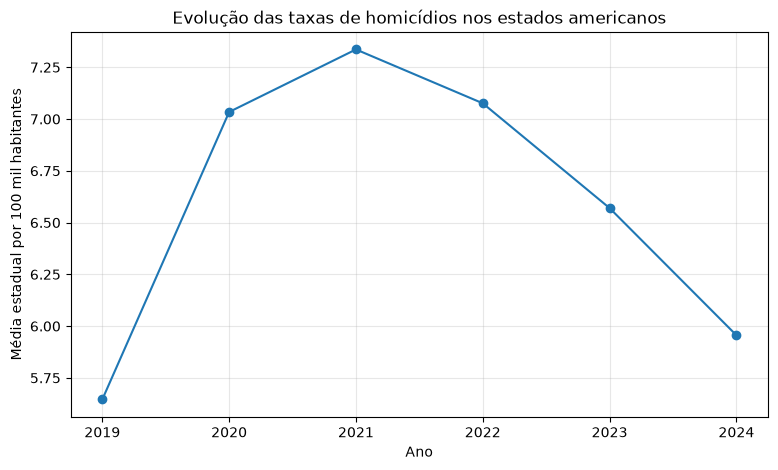

In [7]:
import matplotlib.pyplot as plt

media_anual = df.groupby("period")["rate"].mean()

display(media_anual)

media_anual.plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

plt.title("Evolução das taxas de homicídios nos estados americanos")
plt.xlabel("Ano")
plt.ylabel("Média estadual por 100 mil habitantes")
plt.grid(alpha=0.3)
plt.show()

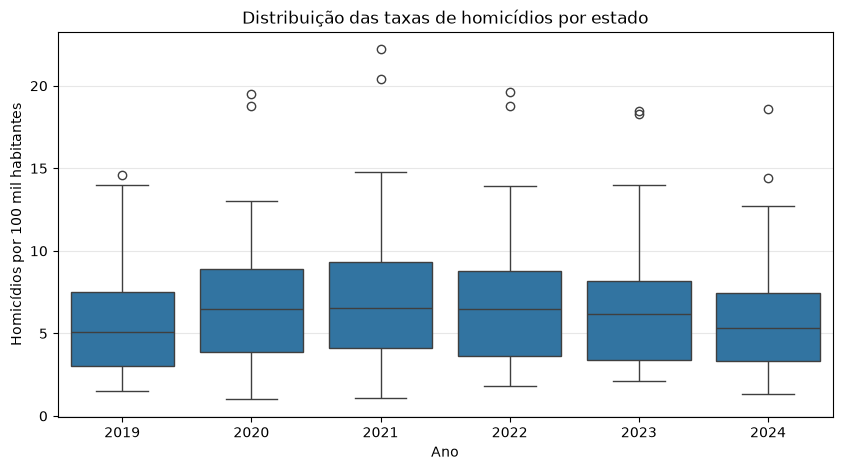

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="period",
    y="rate"
)

plt.title("Distribuição das taxas de homicídios por estado")
plt.xlabel("Ano")
plt.ylabel("Homicídios por 100 mil habitantes")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [9]:
dados_2024 = df[df["period"] == 2024]

ranking = dados_2024.sort_values(
    by="rate",
    ascending=False
)

print("10 maiores taxas:")
display(ranking[["name", "rate"]].head(10))

print("10 menores taxas:")
display(ranking[["name", "rate"]].tail(10).sort_values("rate"))

10 maiores taxas:


,name,rate
149,Mississippi,18.6
113,Louisiana,14.4
191,New Mexico,12.7
5,Alabama,12.6
257,Tennessee,9.8
245,South Carolina,9.4
65,Georgia,9.1
155,Missouri,9.0
125,Maryland,8.6
83,Illinois,8.4


10 menores taxas:


,name,rate
179,New Hampshire,1.3
77,Idaho,1.8
239,Rhode Island,1.8
131,Massachusetts,2.2
269,Utah,2.4
119,Maine,2.4
209,North Dakota,2.6
71,Hawaii,2.7
185,New Jersey,2.8
41,Connecticut,2.9


In [9]:
A análise das taxas de homicídios em 2024 mostrou diferenças expressivas entre os estados americanos. Mississippi apresentou a maior taxa (18,6), enquanto New Hampshire registrou a menor (1,3) por 100 mil habitantes.

Essas diferenças são descritivas e não permitem estabelecer uma relação causal com a legislação sobre armas de fogo. Para investigar a contribuição dessas leis à previsão dos homicídios, será necessário integrar informações legislativas e socioeconômicas.

10 maiores taxas:


,name,rate
149,Mississippi,18.6
113,Louisiana,14.4
191,New Mexico,12.7
5,Alabama,12.6
257,Tennessee,9.8
245,South Carolina,9.4
65,Georgia,9.1
155,Missouri,9.0
125,Maryland,8.6
83,Illinois,8.4


10 menores taxas:


,name,rate
179,New Hampshire,1.3
77,Idaho,1.8
239,Rhode Island,1.8
131,Massachusetts,2.2
269,Utah,2.4
119,Maine,2.4
209,North Dakota,2.6
71,Hawaii,2.7
185,New Jersey,2.8
41,Connecticut,2.9
